# H15 Part A · Step 3 · The training recipe, and the pipeline check

The review of **step 3** of [the plan](../../../docs/drivejepa-perception-sidecar-A.md) (§6 and §9). It
reads the recipe out of the code that trains, then the pipeline check: **epoch 1 of v1's 12-epoch
schedule** (`part-a-pipeline`, run `H15.r1`), read on the select logs only.

**What the pipeline check is, and is not.** It runs the whole path (preflight, data, model, loss,
optimiser, telemetry, select readout, checkpoint, summary) on all 94,195 train samples, for one epoch of
the schedule a real run uses. Its select numbers after one epoch of twelve are a smoke reading: they show
that the pipeline learns, not how well the side-car does. No report-log number exists yet (`--no-report`).

1. the recipe, as the code has it;
2. the schedule, planned and run;
3. the preflight, as the run recorded it;
4. the first epoch, step by step;
5. the end of the epoch, on the select logs;
6. what it says about the full runs: time, memory, disk;
7. the checklist.

Run it with Drive-JEPA's interpreter. Section 6 times a few training steps on a GPU if one is free.

In [1]:
import inspect
import json
import time
import os
import re
import sys
import warnings
from pathlib import Path

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "gallops").is_dir())
sys.path.insert(0, str(REPO / "src"))
os.environ.setdefault("GALLOPS_CONFIG", str(REPO / "gallops.toml"))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from gallops.config import SiteConfig
from gallops.drivejepa_perception import navsim_data, sidecar, train_sidecar, views
from gallops.drivejepa_perception import targets as tg

views.use_style()
pd.set_option("display.precision", 4)
cfg = SiteConfig.load()
RUNS = Path(cfg.resolve("{runs}")) / "drivejepa_perception"
RUN = RUNS / "part-a" / "r1-pipeline-v1-s0"
run = json.loads((RUN / "run.json").read_text())
steps = pd.DataFrame([json.loads(l) for l in (RUN / "steps.jsonl").read_text().splitlines()])
epochs = [json.loads(l) for l in (RUN / "metrics.jsonl").read_text().splitlines()]
summary = json.loads((RUN / "summary.json").read_text())
print(f"run H15.r1: trained from {run['train_git_sha'][:7]}, {run['params']:,} parameters, "
      f"{len(steps)} lines of steps.jsonl, {len(epochs)} epoch(s) in metrics.jsonl")

run H15.r1: trained from d1bacdc, 4,388,342 parameters, 29 lines of steps.jsonl, 1 epoch(s) in metrics.jsonl


## 1. The recipe, as the code has it

Read from `train_sidecar`'s constants, PyTorch's defaults for the optimiser and the loss scaler, and the
run's own arguments (`run.json`). The architecture and the data flow:

![The side-car](../figures/part-a-sidecar.png)

![One training run](../figures/part-a-training.png)

In [2]:
adamw = inspect.signature(torch.optim.AdamW).parameters
scaler = inspect.signature(torch.cuda.amp.GradScaler).parameters
args = run["args"]
recipe = {
    "optimiser": "AdamW",
    "learning rate": train_sidecar.LR,
    "betas, eps": f"{adamw['betas'].default}, {adamw['eps'].default}",
    "weight decay (decoupled, every parameter)": train_sidecar.WEIGHT_DECAY,
    "schedule": "cosine per optimizer step, from 1 to 0 over the run (lr_factor), no warmup",
    "batch (samples)": train_sidecar.BATCH,
    "steps per epoch (drop_last)": run["steps_per_epoch"],
    "epochs in the schedule": args["epochs"],
    "steps in the schedule": run["schedule_steps"],
    "epochs this run trained (--stop-after)": args["stop_after"],
    "precision": "fp16 autocast forward, fp32 loss",
    "GradScaler: start, growth, backoff, interval": f"{scaler['init_scale'].default:g}, {scaler['growth_factor'].default}, "
    f"{scaler['backoff_factor'].default}, {scaler['growth_interval'].default}",
    "gradient clip (global L2, after unscaling)": train_sidecar.CLIP,
    "loader": "8 workers, shuffled by a generator seeded with the run's seed, pinned memory",
    "seed": args["seed"],
    "input": f"tap {args['tap']}: the ViT's output, 512 × 1024 fp16",
    "variant": f"{args['variant']}: d {args['d_model']}, {args['heads']} heads, FFN {args['ffn']}, "
    f"{args['layers']} layers, {args['queries']} queries",
    "report logs read": not args["no_report"],
    "telemetry": f"every {args['log_every']} steps (steps.jsonl), every epoch (metrics.jsonl)",
}
pd.Series(recipe, name="value").to_frame()

,value
optimiser,AdamW
learning rate,0.0002
"betas, eps","(0.9, 0.999), 1e-08"
"weight decay (decoupled, every parameter)",0.01
schedule,"cosine per optimizer step, from 1 to 0 over th..."
batch (samples),64
steps per epoch (drop_last),1471
epochs in the schedule,12
steps in the schedule,17652
epochs this run trained (--stop-after),1


## 2. The schedule: planned, and the part that ran

The pipeline check is epoch 1 **of the 12-epoch schedule** (`--stop-after 1`), so its learning rate is the
real run's first epoch, not a 1-epoch cosine squashed to zero. The logged learning rate (each dot is the
mean of 50 steps) must sit on the planned curve.

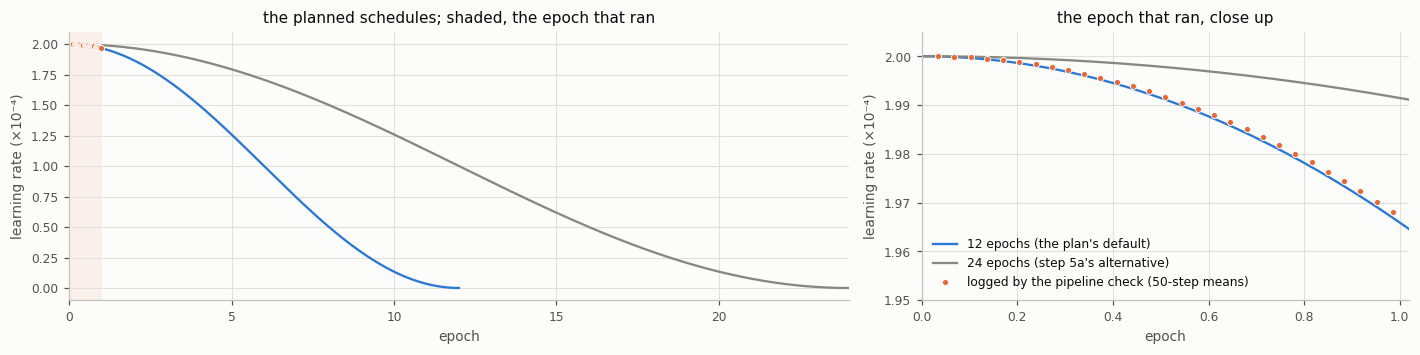

largest gap between the logged and the planned learning rate: 1.91e-09


In [3]:
per_epoch = run["steps_per_epoch"]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.3), gridspec_kw={"width_ratios": [1.6, 1.0]})
for ax, xmax in zip(axes, (24, 1.02)):
    for n_epochs, colour, label in ((12, views.CLASS_COLOURS[0], "12 epochs (the plan's default)"),
                                    (24, views.GREY, "24 epochs (step 5a's alternative)")):
        s_all = np.arange(0, per_epoch * n_epochs + 1, 7)
        ax.plot(s_all / per_epoch, [1e4 * train_sidecar.LR * train_sidecar.lr_factor(i, per_epoch * n_epochs) for i in s_all],
                color=colour, label=label)
    ax.plot(steps.step / per_epoch, 1e4 * steps.lr, "o", ms=4, color=views.CLASS_COLOURS[1], mec=views.SURFACE, mew=0.6,
            label="logged by the pipeline check (50-step means)")
    ax.set_xlim(0, xmax)
    ax.set_xlabel("epoch")
    ax.set_ylabel("learning rate (×10⁻⁴)")
axes[0].axvspan(0, 1, color=views.CLASS_COLOURS[1], alpha=0.08, lw=0)
axes[0].set_title("the planned schedules; shaded, the epoch that ran")
axes[1].set_ylim(1.95, 2.005)
axes[1].set_title("the epoch that ran, close up")
axes[1].legend(loc="lower left")
plt.tight_layout()
plt.show()
planned = np.array([train_sidecar.LR * train_sidecar.lr_factor(int(s) - 25, run["schedule_steps"]) for s in steps.step])
print(f"largest gap between the logged and the planned learning rate: {np.abs(steps.lr - planned).max():.2e}")

The logged value is a 50-step mean, compared with the planned value 25 steps before the line's step (the
window's middle). The first step was skipped by the loss scaler (an overflow at its start scale), which
PyTorch reports as "`lr_scheduler.step()` before `optimizer.step()`": each skipped step (three here, all
in the first 50) puts the schedule one step ahead of the optimiser, 3 steps in 17,652.

## 3. The preflight, as the run recorded it

Every check ran before the first step (`preflight.run`); the run's `run.json` keeps what each measured.

In [4]:
pf = run["preflight"]
inputs = pf["inputs"]
checks = [
    ("code committed (src/, tests/)", pf["code"]["git_clean"], "required"),
    ("test suite under the training interpreter", pf["code"]["tests"], "no failure"),
    ("rows: labels = token cache = ViT-out cache", f"{pf['data']['label_rows']:,} = {pf['data']['cache_rows']:,} = {pf['data']['vit_rows']:,}", "equal"),
    ("rows read: train, select, report", f"{pf['data']['train_rows']:,}, {pf['data']['select_rows']:,}, {pf['data']['report_rows']:,}", "inside their splits"),
    ("labels against NAVSIM's code, 8 windows", "no problem" if not pf["labels"]["problems"] else pf["labels"]["problems"], "no problem"),
    ("live post-projector tokens − cache, largest", f"{inputs['token_max_diff']:.4f}", "≤ 0.01"),
    ("live picks = cached picks", f"{inputs['picks_equal']} of {len(inputs['rows'])}", "all"),
    ("live ViT output − ViT-out cache, largest", f"{inputs['vit_out']['max_abs']:.4f}", "≤ 0.1"),
    ("live ViT output − ViT-out cache, mean", f"{inputs['vit_out']['mean_abs']:.2e}", "≤ 1e-3"),
    ("u of a point 20 m straight ahead (512-wide image)", ", ".join(f"{u:.1f}" for u in pf["projection"]["u_of_20m_ahead"]), "within 64 of 256"),
]
pd.DataFrame(checks, columns=["check", "measured", "limit"]).set_index("check")

,measured,limit
check,,
"code committed (src/, tests/)",True,required
test suite under the training interpreter,"238 passed, 95 skipped in 17.12s",no failure
rows: labels = token cache = ViT-out cache,"103,288 = 103,288 = 103,288",equal
"rows read: train, select, report","94,195, 4,457, 4,636",inside their splits
"labels against NAVSIM's code, 8 windows",no problem,no problem
"live post-projector tokens − cache, largest",0.0038,≤ 0.01
live picks = cached picks,6 of 6,all
"live ViT output − ViT-out cache, largest",0.0156,≤ 0.1
"live ViT output − ViT-out cache, mean",3.56e-04,≤ 1e-3


The ViT-output check is new in the rerun: the first pass held only the post-projector tokens to the live
model, while the side-car reads the ViT's output. Its largest difference, 0.0156, is one fp16 step at the
output's scale; the mean is 3.6e-4.

## 4. The first epoch, step by step

Each point is the mean over 50 steps (`steps.jsonl`). Layers are shades of one hue, light to dark: layer 0
(first) to layer 2 (last, the one read).

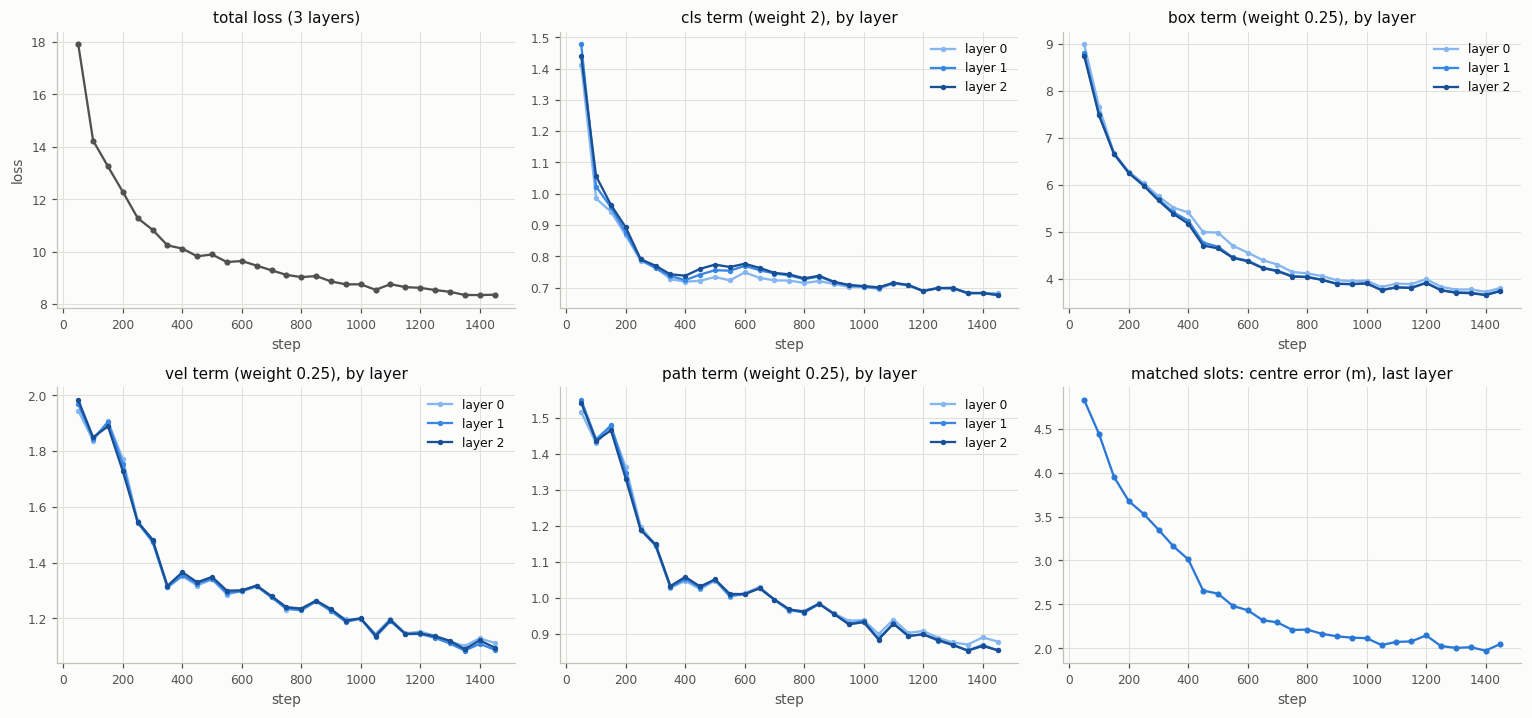

In [5]:
LAYERS = ("#86b6ef", "#3987e5", "#184f95")
fig, axes = plt.subplots(2, 3, figsize=(14, 6.6))
ax = axes[0, 0]
ax.plot(steps.step, steps.loss, "o-", ms=3, color=views.INK_2)
ax.set_title("total loss (3 layers)")
ax.set_ylabel("loss")
for ax, (term, weight) in zip([axes[0, 1], axes[0, 2], axes[1, 0], axes[1, 1]], (("cls", 2), ("box", 0.25), ("vel", 0.25), ("path", 0.25))):
    for l in range(3):
        ax.plot(steps.step, steps[f"{term}{l}"], "o-", ms=2.5, color=LAYERS[l], label=f"layer {l}")
    ax.set_title(f"{term} term (weight {weight}), by layer")
    ax.legend()
ax = axes[1, 2]
ax.plot(steps.step, steps.match_centre_m, "o-", ms=3, color=views.CLASS_COLOURS[0])
ax.set_title("matched slots: centre error (m), last layer")
for ax in axes.ravel():
    ax.set_xlabel("step")
plt.tight_layout()
plt.show()

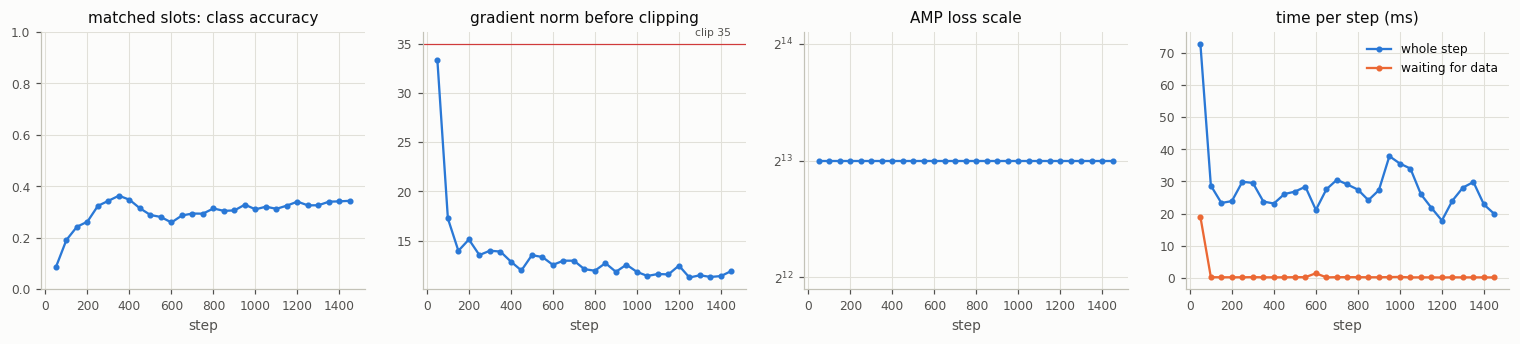

steps 1471, clipped 16, skipped by the loss scaler 3 (0.20%); peak GPU memory 3.7 GB; 449 targets a batch on average


In [6]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
ax = axes[0]
ax.plot(steps.step, steps.match_class_acc, "o-", ms=3, color=views.CLASS_COLOURS[0])
ax.set_title("matched slots: class accuracy")
ax.set_ylim(0, 1)
ax = axes[1]
ax.plot(steps.step, steps.grad_norm, "o-", ms=3, color=views.CLASS_COLOURS[0])
ax.axhline(train_sidecar.CLIP, color=views.MISS, lw=0.8)
ax.text(steps.step.max(), train_sidecar.CLIP + 0.8, "clip 35", ha="right", fontsize=7, color=views.INK_2)
ax.set_title("gradient norm before clipping")
ax = axes[2]
ax.plot(steps.step, steps.amp_scale, "o-", ms=3, color=views.CLASS_COLOURS[0])
ax.set_yscale("log", base=2)
ax.set_title("AMP loss scale")
ax = axes[3]
ax.plot(steps.step, 1000 * steps.step_s, "o-", ms=3, color=views.CLASS_COLOURS[0], label="whole step")
ax.plot(steps.step, 1000 * steps.data_s, "o-", ms=3, color=views.CLASS_COLOURS[1], label="waiting for data")
ax.set_title("time per step (ms)")
ax.legend()
for ax in axes:
    ax.set_xlabel("step")
plt.tight_layout()
plt.show()
e1 = epochs[0]
print(f"steps {e1['steps']}, clipped {e1['clipped_steps']}, skipped by the loss scaler {e1['skipped_steps']} "
      f"({e1['skipped_steps'] / e1['steps']:.2%}); peak GPU memory {e1['max_memory_gb']:.1f} GB; "
      f"{e1['train']['targets']:.0f} targets a batch on average")

In [7]:
last = steps.iloc[-1]
first = steps.iloc[0]
pd.DataFrame(
    {f"layer {l}": {f"{term}, steps 1–50": first[f"{term}{l}"] for term in ("cls", "box", "vel", "path")}
     | {f"{term}, last 50 steps": last[f"{term}{l}"] for term in ("cls", "box", "vel", "path")}
     for l in range(3)}
) if sys.version_info >= (3, 9) else None

,layer 0,layer 1,layer 2
"cls, steps 1–50",1.4114,1.4771,1.4389
"box, steps 1–50",8.9822,8.7997,8.7369
"vel, steps 1–50",1.9451,1.9687,1.9834
"path, steps 1–50",1.5158,1.5500,1.5419
"cls, last 50 steps",0.6817,0.6768,0.6759
"box, last 50 steps",3.8026,3.7478,3.7358
"vel, last 50 steps",1.1118,1.0870,1.0950
"path, last 50 steps",0.8788,0.8546,0.8548


**Reading the curves.**
- The loss falls from 17.9 (steps 1–50) to 8.4 (steps 1,401–1,450) and is still falling: nothing stalls.
- **By layer** (the table above): over the last 50 steps every term is lower in layers 1 and 2 than in
  layer 0, most clearly the box term (3.80 → 3.74) and the path term (0.88 → 0.85). In mid-epoch (steps
  400–900) the class term's later layers sat slightly above the first and then came level: the decoder's
  refinement takes hold during the epoch, not from its start.
- Class accuracy of the matched slots climbs from 0.09 to about 0.34: most matched slots still say "none"
  after one epoch, which the readout below shows as recall under precision.
- The gradient norm starts near the clip (16 steps clipped, all early) and settles near 12.
- The loss scaler backed off three times in the first 50 steps (65,536 → 8,192), then held.
- The loader waits about 1 ms per step against 20–30 ms of compute: the token cache is in the page cache.

## 5. The end of epoch 1, on the select logs (a smoke reading)

The full readout (`evaluate.readout`) on the 4,457 select samples after the epoch. For orientation only:
the first pass's v1 at seed 0 read select F1 0.669 at its kept epoch 11 (README, B3.1's preflight); after
one epoch of twelve, F1 0.477.

In [8]:
sel = e1["select"]
names = views.CLASS_NAMES
smoke = {
    "recall at 2 m, within 30 m": sel["recall_2m_within_30m"],
    "precision at 2 m, within 30 m": sel["precision_2m_within_30m"],
    "F1 within 30 m (the kept-epoch rule)": e1["f1_30m"],
    "recall, all ranges": sel["recall_2m"],
    "precision, all ranges": sel["precision_2m"],
    **{f"recall {lo:g}–{hi:g} m": v for (lo, hi), v in zip(((0, 20), (20, 30), (30, 50)), sel["recall_by_range"])},
    **{f"recall within 30 m, {n}s": v for n, v in zip(names, sel["recall_2m_within_30m_by_class"])},
    "moving vehicles within 20 m, recall": sel["moving_vehicles_20m_recall"],
    "centre error of hits (m)": sel["centre_error_m"],
    "velocity error of hits (m/s)": sel["velocity_error_mps"],
    "1 s path FDE, moving hits: side-car (m)": sel["path_fde_1s_model_moving"],
    "1 s path FDE, moving hits: constant velocity, its own (m)": sel["path_fde_1s_cv_pred_moving"],
    "1 s path FDE, moving hits: constant velocity, the label's (m)": sel["path_fde_1s_cv_label_moving"],
    "lead-vehicle gap error (m)": sel["lead_gap_mae_m"],
    "lead-vehicle gap error, train-mean prior (m)": sel["lead_gap_prior_mae_m"],
    "detections per sample (confidence ≥ 0.5)": sel["detections_per_sample"],
    "targets": sel["targets"],
}
pd.Series(smoke, name="select, after epoch 1 of 12").to_frame()

,"select, after epoch 1 of 12"
"recall at 2 m, within 30 m",0.4052
"precision at 2 m, within 30 m",0.5783
F1 within 30 m (the kept-epoch rule),0.4766
"recall, all ranges",0.2269
"precision, all ranges",0.4940
recall 0–20 m,0.6380
recall 20–30 m,0.2554
recall 30–50 m,0.0804
"recall within 30 m, vehicles",0.5325
"recall within 30 m, pedestrians",0.2414


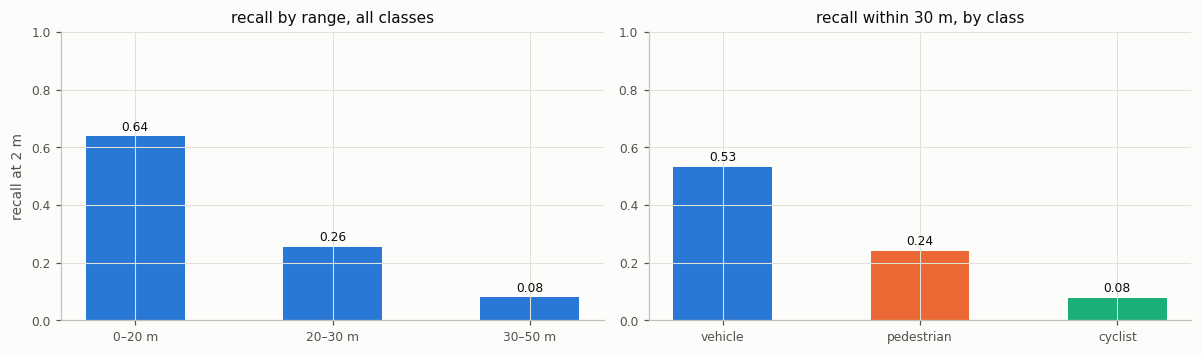

sight check on select, after training (summary.json): {'with_tokens': 3.336549248373345, 'tokens_zeroed': 0.0}


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
ax = axes[0]
ax.bar(range(3), sel["recall_by_range"], width=0.5, color=views.CLASS_COLOURS[0])
ax.set_xticks(range(3))
ax.set_xticklabels(["0–20 m", "20–30 m", "30–50 m"])
ax.set_ylim(0, 1)
ax.set_ylabel("recall at 2 m")
ax.set_title("recall by range, all classes")
for i, v in enumerate(sel["recall_by_range"]):
    ax.text(i, v + 0.02, f"{v:.2f}", ha="center", fontsize=8)
ax = axes[1]
ax.bar(range(3), sel["recall_2m_within_30m_by_class"], width=0.5, color=list(views.CLASS_COLOURS))
ax.set_xticks(range(3))
ax.set_xticklabels(names)
ax.set_ylim(0, 1)
ax.set_title("recall within 30 m, by class")
for i, v in enumerate(sel["recall_2m_within_30m_by_class"]):
    ax.text(i, v + 0.02, f"{v:.2f}", ha="center", fontsize=8)
plt.tight_layout()
plt.show()
print("sight check on select, after training (summary.json):", summary["sight_select"])

**Reading it.** After one epoch the side-car already finds most near agents (recall 0.64 within 20 m) and
few far ones (0.08 beyond 30 m); vehicles well ahead of pedestrians. It is conservative: 3.3 detections a
sample against 7.3 targets. Its 1 s paths are no better than constant velocity from its own velocity yet
(1.472 against 1.470 m), so the path head has learnt only the velocity's direction so far. With the tokens
zeroed it detects nothing (0.0 a sample): it reads the image.

## 6. What it says about the full runs: time, memory, disk

The pipeline check took **46 s for the epoch, including the select readout**, on a GPU other jobs kept at
full load. Below, the same training step timed for each variant on one batch of 64 real train samples
(fp16 autocast, the run's optimiser and loss; median of 20 steps after 5 of warm-up), to scale it.

In [10]:
def freest_gpu():
    """The visible GPU with the most free memory: the GPUs are shared, and busy ones time slower."""
    free = [torch.cuda.mem_get_info(i)[0] for i in range(torch.cuda.device_count())]
    return torch.device("cuda", int(np.argmax(free)))


def step_time(arch, batch, device, steps=20, warmup=5):
    torch.manual_seed(0)
    model = train_sidecar.build_model({"tap": "vit_out", **arch}).to(device)
    optimiser = torch.optim.AdamW(model.parameters(), lr=train_sidecar.LR, weight_decay=train_sidecar.WEIGHT_DECAY)
    scaler = torch.cuda.amp.GradScaler()
    criterion = sidecar.SideCarLoss()
    batch = {k: v.to(device) for k, v in batch.items()}
    torch.cuda.reset_peak_memory_stats(device)
    times = []
    for i in range(warmup + steps):
        torch.cuda.synchronize(device)
        t0 = time.time()
        with torch.autocast("cuda", dtype=torch.float16):
            outs = model(batch["tokens"], batch["projection"])
        loss, _ = criterion(outs, batch)
        optimiser.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimiser)
        torch.nn.utils.clip_grad_norm_(model.parameters(), train_sidecar.CLIP)
        scaler.step(optimiser)
        scaler.update()
        torch.cuda.synchronize(device)
        if i >= warmup:
            times.append(time.time() - t0)
    out = float(np.median(times)), torch.cuda.max_memory_allocated(device) / 1e9, sum(p.numel() for p in model.parameters())
    del model, optimiser
    torch.cuda.empty_cache()
    return out


labels = dict(np.load(RUNS / "labels-v1" / "labels.npz"))
logs = json.loads((RUNS / "labels-v1" / "manifest.json").read_text())["logs"]
token_logs = np.array([logs[i] for i in labels["log_id"]])
splits = json.loads((REPO / "recipes" / "drivejepa_perception" / "splits.json").read_text())
train_rows = np.flatnonzero(np.isin(token_logs, splits["train"]))
proj = tg.front_projection(np.asarray(np.load(RUNS / "tokens-v1" / "lidar2img.npy", mmap_mode="r"))).astype(np.float32)
vit = np.load(RUNS / "tokens-vit-v1" / "vit_out.npy", mmap_mode="r")
picked = np.random.default_rng(0).choice(train_rows, train_sidecar.BATCH, replace=False)
targets = {int(r): tg.build(navsim_data.agents_of(labels, r), proj[r]) for r in picked}
batch64 = torch.utils.data.default_collate([train_sidecar.Rows(vit, int, picked, proj, targets)[i] for i in range(len(picked))])

timing = {}
if torch.cuda.is_available():
    device = freest_gpu()
    for name, arch in train_sidecar.VARIANTS.items():
        seconds, memory, params = step_time(arch, batch64, device)
        timing[name] = {"parameters (M)": params / 1e6, "step (ms)": 1000 * seconds, "peak memory (GB)": memory}
    timing = pd.DataFrame(timing).T
    measured_epoch = e1["seconds"]
    v1_step = timing.loc["v1", "step (ms)"]
    timing["epoch (s), scaled from the check's 46 s"] = measured_epoch * timing["step (ms)"] / v1_step
    timing["12-epoch run (min)"] = 12 * timing["epoch (s), scaled from the check's 46 s"] / 60
    timing["checkpoint (MB)"] = 4 * timing["parameters (M)"]
else:
    print("no GPU visible: the timing is skipped")
timing

,parameters (M),step (ms),peak memory (GB),"epoch (s), scaled from the check's 46 s",12-epoch run (min),checkpoint (MB)
v1,4.3883,15.0182,0.7861,46.0000,9.2000,17.5534
v2,8.3686,37.3038,1.7987,114.2595,22.8519,33.4745
v3,18.4441,42.6725,2.7219,130.7036,26.1407,73.7766


The steps were timed on whichever GPU had the most free memory, and other jobs share it: the
absolute step times move with their load (this table's v1 step need not match the check's 20–30 ms).
The budget therefore scales the check's **measured** 46 s epoch by the **ratio** of step times, which
assumes an epoch costs what its steps cost; that held for the check (data waits of about 1 ms).

**Step 5's budget**, from the table: 5a is v1, v2 and v3 for 12 epochs plus v1 for 24; 5b is two or three
more runs of the chosen variant plus the blind control.

In [11]:
if len(timing):
    minutes = timing["12-epoch run (min)"]
    plan = {
        "5a: v1, v2, v3 (12 epochs) and v1 (24 epochs)": minutes["v1"] * 3 + minutes["v2"] + minutes["v3"],
        "5b, if v1 is chosen at 12 epochs: seeds 1, 2 + blind": 3 * minutes["v1"],
        "5b, if v3 is chosen at 24 epochs: seeds 0, 1, 2 + blind": 4 * 2 * minutes["v3"],
    }
    display(pd.Series(plan, name="wall-clock minutes, one GPU").round(0).to_frame())

,"wall-clock minutes, one GPU"
"5a: v1, v2, v3 (12 epochs) and v1 (24 epochs)",77.0
"5b, if v1 is chosen at 12 epochs: seeds 1, 2 + blind",28.0
"5b, if v3 is chosen at 24 epochs: seeds 0, 1, 2 + blind",209.0


## 7. The checklist (plan §6.7)

| What would be wrong | What epoch 1 showed |
|---|---|
| a loss that rises, or stalls in the first few hundred steps | falls throughout: 17.9 → 8.4 |
| later layers no better than the first | every term lower in layers 1–2 than in layer 0 by the end of the epoch |
| clipping on most steps | 16 of 1,471, all early |
| repeated AMP overflows | 3 in the first 50 steps (0.2%; gate G3 allows 1%), none after |
| class accuracy stuck at the "none"-heavy start | rising, 0.09 → 0.34 |
| loader waits as long as the steps | about 1 ms against 20–30 ms |

**Nothing here blocks step 5.** What epoch 1 cannot show (whether the later epochs keep improving, and
where the select F1 tops out) is what 5a's curves are for.